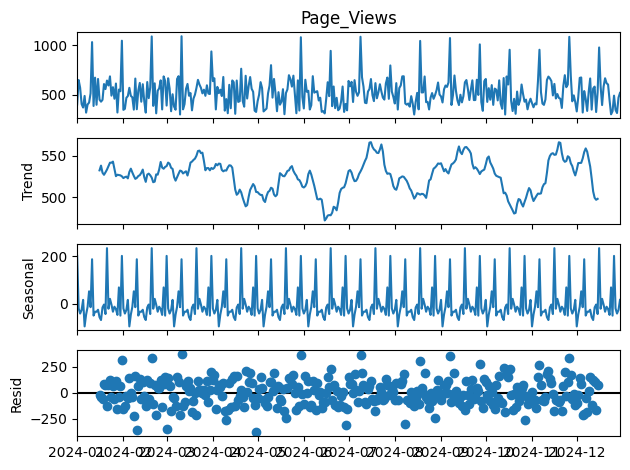

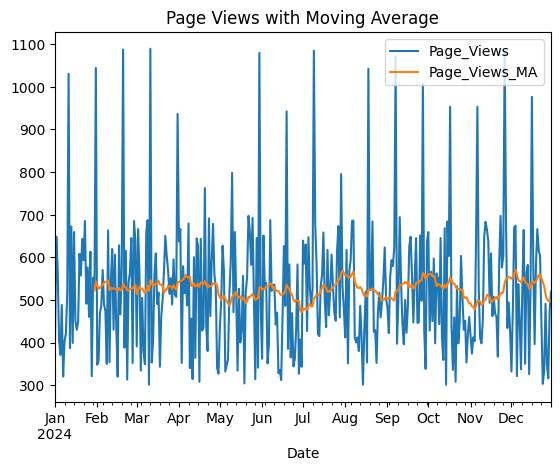

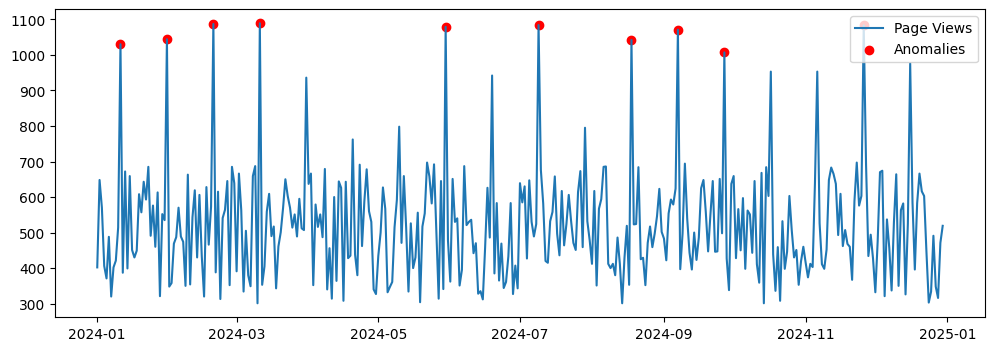

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose

dates = pd.date_range(start='2024-01-01', periods=365, freq='D')

np.random.seed(42)

page_views = 500 + np.random.randint(-200, 200, 365)

for i in range(10, 365, 20):
    page_views[i] += 400

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': page_views
})

data.set_index('Date', inplace=True)

decomposition = seasonal_decompose(data['Page_Views'], model='additive', period=30)
decomposition.plot()
plt.show()

data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()

data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]
plt.figure(figsize=(12, 4))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()